# Modèle court : combien de questions suffisent ?

**Règle d'arrêt, fixée avant de regarder la courbe :** on retient le plus petit ensemble de questions dont le F1 macro de validation reste à moins de 0,02 de celui du modèle complet.

Les résultats supposent vraie notre hypothèse sur les libellés de la Tanzanie (voir `01_eda.ipynb`, section 3).

In [1]:
import sys

sys.path.insert(0, "..")  # remonte d'un dossier pour trouver src/
from src.decoupage import decouper, evaluer

X_ent, X_val, X_test, y_ent, y_val, y_test = decouper()  # découpage commun du groupe
print(X_ent.shape, X_val.shape, X_test.shape)

ECART_MAX = 0.02  # la règle d'arrêt

(16466, 10) (3529, 10) (3529, 10)


In [2]:
import numpy as np
from sklearn.metrics import f1_score

from src.modele_court import construire_modele, meilleur_seuil


def evaluer_variables(variables):
    """Entraîne sur X_ent, choisit le seuil sur la validation, renvoie (modèle, seuil, F1 macro)."""
    modele = construire_modele(variables)
    modele.fit(X_ent[variables], y_ent)  # apprentissage uniquement sur l'entraînement
    probabilites = modele.predict_proba(X_val[variables])[:, 1]  # probabilité d'avoir un compte
    seuil, f1_macro = meilleur_seuil(y_val, probabilites)
    return modele, seuil, f1_macro

In [3]:
toutes_variables = list(X_ent.columns)
modele_complet, seuil_complet, f1_complet = evaluer_variables(toutes_variables)

print("Seuil retenu :", round(seuil_complet, 2))
print("F1 macro de validation :", round(f1_complet, 2))
print("Référence naïve à battre : 0.46")

probabilites_complet = modele_complet.predict_proba(X_val)[:, 1]
predictions_complet = (probabilites_complet >= seuil_complet).astype(int)
evaluer(X_val, y_val, predictions_complet)  # F1 macro global, par pays et par genre

Seuil retenu : 0.34
F1 macro de validation : 0.74
Référence naïve à battre : 0.46


,effectif,f1_macro
groupe,,
Global,3529,0.7418
country = Kenya,911,0.7359
country = Rwanda,1310,0.7017
country = Tanzania,993,0.7476
country = Uganda,315,0.7130
gender_of_respondent = Female,2077,0.7312
gender_of_respondent = Male,1452,0.7422


### Modèle complet (10 questions) : résultats par groupe

Le F1 macro de validation du modèle complet est de 0,74, contre 0,46 pour la référence naïve. Le seuil retenu est de 0,34, inférieur à 0,5 : avec 14 % de comptes, le seuil par défaut n'est pas le meilleur.

**Par pays** : le Rwanda a le score le plus bas (0,70) et la Tanzanie le plus haut (0,75). Le Kenya (0,74) et l'Ouganda (0,71) sont intermédiaires. Tous les pays restent très au-dessus de la référence naïve (entre 0,43 et 0,48 selon le pays).
L'Ouganda ne compte que 315 personnes en validation : son score est moins stable que les autres.

**Par genre** : l'écart est faible, 0,73 pour les femmes et 0,74 pour les hommes.

**Limites** : le seuil est choisi sur la même validation que celle qui sert à mesurer le score, donc ces chiffres sont un peu optimistes. Le test final, utilisé une seule fois, donnera le chiffre à rapporter.
Les scores de la Tanzanie supposent vraie notre hypothèse sur ses libellés : un bon score ne la confirme pas.

In [4]:
variables_restantes = list(toutes_variables)  # variables pas encore retenues
variables_retenues = []  # variables retenues, dans l'ordre où on les ajoute
historique = []  # une ligne par nombre de questions

while variables_restantes:
    essais = {}
    for variable in variables_restantes:
        _, _, f1_macro = evaluer_variables(variables_retenues + [variable])  # modèle avec cette variable en plus
        essais[variable] = f1_macro

    meilleure = max(essais, key=lambda variable: essais[variable])  # variable dont le F1 macro est le plus haut
    variables_retenues.append(meilleure)
    variables_restantes.remove(meilleure)
    historique.append({
        "nombre_questions": len(variables_retenues),
        "variable_ajoutee": meilleure,
        "f1_macro": essais[meilleure],
    })

In [5]:
import pandas as pd

courbe = pd.DataFrame(historique)
courbe["ecart_au_complet"] = f1_complet - courbe["f1_macro"]  # écart au modèle à 10 questions

suffisants = courbe[courbe["ecart_au_complet"] <= ECART_MAX]  # ensembles qui respectent la règle écrite en haut
nombre_retenu = int(suffisants["nombre_questions"].min())  # le plus petit d'entre eux
variables_courtes = list(courbe.loc[courbe["nombre_questions"] <= nombre_retenu, "variable_ajoutee"])

print("Nombre de questions retenu :", nombre_retenu)
print("Questions retenues :", variables_courtes)
courbe.round(2)  # arrondi pour l'affichage, les calculs ci-dessus gardent toute la précision

Nombre de questions retenu : 3
Questions retenues : ['job_type', 'education_level', 'country']


,nombre_questions,variable_ajoutee,f1_macro,ecart_au_complet
0,1,job_type,0.67,0.07
1,2,education_level,0.70,0.04
2,3,country,0.73,0.01
3,4,age_of_respondent,0.74,0.00
4,5,gender_of_respondent,0.74,0.00
5,6,relationship_with_head,0.74,-0.00
6,7,household_size,0.74,-0.00
7,8,location_type,0.74,0.00
8,9,cellphone_access,0.74,0.00
9,10,marital_status,0.74,0.00


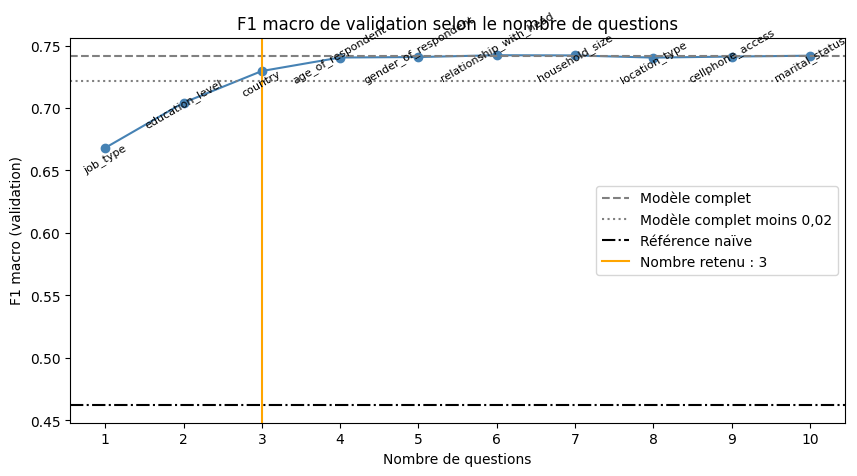

In [6]:
import matplotlib.pyplot as plt

f1_naif = float(f1_score(y_val, np.zeros(len(y_val), dtype=int), average="macro", labels=[0, 1], zero_division=0))  # référence naïve, convertie en nombre simple

figure, axe = plt.subplots(figsize=(10, 5))
axe.plot(courbe["nombre_questions"], courbe["f1_macro"], marker="o", color="steelblue")

for _, ligne in courbe.iterrows():  # écrit le nom de la variable ajoutée sous chaque point
    axe.annotate(ligne["variable_ajoutee"], (ligne["nombre_questions"], ligne["f1_macro"]),
                 textcoords="offset points", xytext=(0, -18), ha="center", fontsize=8, rotation=30)

axe.axhline(f1_complet, color="gray", linestyle="--", label="Modèle complet")
axe.axhline(f1_complet - ECART_MAX, color="gray", linestyle=":", label="Modèle complet moins 0,02")
axe.axhline(f1_naif, color="black", linestyle="-.", label="Référence naïve")
axe.axvline(nombre_retenu, color="orange", label=f"Nombre retenu : {nombre_retenu}")

axe.set_title("F1 macro de validation selon le nombre de questions")
axe.set_xlabel("Nombre de questions")
axe.set_ylabel("F1 macro (validation)")
axe.set_xticks(courbe["nombre_questions"])
axe.legend()
plt.show()

### Interprétation : combien de questions suffisent ?

Le F1 macro de validation passe de 0,67 avec une seule question (`job_type`) à 0,70 avec deux (`education_level`), puis à 0,73 avec trois (`country`). Au-delà de 4 questions, la courbe est plate à 0,74, comme le modèle complet à 10 questions.

**Nombre retenu : 3 questions** (`job_type`, `education_level`, `country`), selon la règle fixée avant le calcul : un F1 macro à moins de 0,02 du modèle complet. L'écart est d'environ 0,01, et le modèle reste très au-dessus de la référence naïve (0,46).

**Observations**
- Les cinq variables prioritaires de l'EDA ne sont pas toutes retenues : l'emploi, l'éducation et le pays le sont, mais `location_type` et `cellphone_access` arrivent en 8e et 9e position, avec un gain nul.
- Hypothèse (non testée ici) : ces deux variables sont liées à l'emploi et à l'éducation. L'EDA le suggère : l'odds ratio du téléphone passe de 12,9 à 7,4 quand on fixe l'emploi et l'éducation (section 4.8). Une fois ces trois questions posées, elles apportent peu d'information en plus.
- Les différences de 0,00 à 0,01 entre les ensembles de 4 à 10 questions sont trop petites pour être interprétées avec une seule validation de 3 529 personnes. L'ordre des variables au-delà de la 3e ne doit pas être lu comme un classement.

**Limites**
- L'ordre vient d'une sélection pas à pas sur un seul découpage : un autre découpage pourrait donner un ordre légèrement différent.
- `job_type` n'a pas les mêmes modalités selon les pays (EDA, section 3.2 et décision 15). Le modèle court, qui combine `job_type` et `country`, peut en tirer une différence entre pays qui vient du codage.
- Les scores de validation sont légèrement optimistes, car les variables et le seuil sont choisis sur les mêmes données. Seul le test final donnera le chiffre à rapporter.
- Tous les résultats supposent vraie notre hypothèse sur la Tanzanie.

In [7]:
modele_court, seuil_court, f1_court = evaluer_variables(variables_courtes)  # apprend sur X_ent et choisit le seuil sur la validation
print("Questions du modèle court :", variables_courtes)
print("Seuil du modèle court :", round(seuil_court, 2))
print("F1 macro de validation du modèle court :", round(f1_court, 2))

probabilites_court = modele_court.predict_proba(X_val[variables_courtes])[:, 1]  # probabilité d'avoir un compte
predictions_court = (probabilites_court >= seuil_court).astype(int)  # 1 si la probabilité atteint le seuil

resultat_court = evaluer(X_val, y_val, predictions_court)  # on passe X_val complet : evaluer lit country et gender_of_respondent
resultat_complet = evaluer(X_val, y_val, predictions_complet)  # prédictions du modèle complet, calculées à la cellule 3

comparaison = pd.DataFrame({
    "effectif": resultat_court["effectif"],
    "f1_complet": resultat_complet["f1_macro"],
    "f1_court": resultat_court["f1_macro"],
})
comparaison["perte"] = comparaison["f1_complet"] - comparaison["f1_court"]  # ce que l'on perd en posant moins de questions
comparaison.round(2) 

Questions du modèle court : ['job_type', 'education_level', 'country']
Seuil du modèle court : 0.23
F1 macro de validation du modèle court : 0.73


,effectif,f1_complet,f1_court,perte
groupe,,,,
Global,3529,0.74,0.73,0.01
country = Kenya,911,0.74,0.72,0.01
country = Rwanda,1310,0.70,0.68,0.02
country = Tanzania,993,0.75,0.73,0.02
country = Uganda,315,0.71,0.70,0.01
gender_of_respondent = Female,2077,0.73,0.72,0.01
gender_of_respondent = Male,1452,0.74,0.74,0.01


In [8]:
perte_globale = comparaison["perte"].to_dict()["Global"]  # perte moyenne, tous groupes confondus
comparaison_groupes = comparaison.drop(index="Global").copy()  # on retire la ligne globale pour ne garder que les groupes
comparaison_groupes["perte_moins_perte_globale"] = comparaison_groupes["perte"] - perte_globale  # positif = ce groupe perd plus que la moyenne
comparaison_groupes[["effectif", "perte", "perte_moins_perte_globale"]].round(2)

,effectif,perte,perte_moins_perte_globale
groupe,,,
country = Kenya,911,0.01,-0.00
country = Rwanda,1310,0.02,0.01
country = Tanzania,993,0.02,0.01
country = Uganda,315,0.01,-0.00
gender_of_respondent = Female,2077,0.01,0.00
gender_of_respondent = Male,1452,0.01,-0.01


### Modèle court (3 questions) comparé au modèle complet (10 questions)

Le modèle court (`job_type`, `education_level`, `country`) obtient un F1 macro de validation de 0,73, contre 0,74 pour le modèle complet. La perte globale est d'environ 0,01. Le seuil retenu est de 0,23, plus bas que celui du modèle complet (0,34).

**Par pays** : la perte est de 0,01 au Kenya et en Ouganda, et de 0,02 au Rwanda et en Tanzanie. Le Rwanda reste le pays où le score est le plus bas (0,68 contre 0,70 pour le modèle complet).

**Par genre** : la perte est de 0,01 pour les femmes comme pour les hommes (0,72 contre 0,73 pour les femmes, 0,74 contre 0,74 pour les hommes).

**Lecture** : les écarts entre groupes (0,01 ou 0,02) sont trop petits pour affirmer que le modèle court perd davantage dans un pays ou pour un genre. Ils viennent d'un seul découpage de validation, avec seulement 315 personnes pour l'Ouganda. On ne conclut pas à une différence.

**Hypothèse (non testée ici)** : le seuil plus bas du modèle court pourrait venir du fait que trois variables ne produisent qu'un petit nombre de probabilités différentes, ce qui change la meilleure coupure. À vérifier si cela compte pour le rapport.

**Limites** : le seuil est choisi sur la même validation que celle qui mesure le score, donc ces chiffres sont légèrement optimistes. Tous les résultats supposent vraie notre hypothèse sur la Tanzanie.

In [9]:
import joblib

from src.modele_court import CHEMIN_MODELE, VARIABLES_COURTES, entrainer, predire_court

objet_court = entrainer(X_ent, y_ent)  # exactement ce que le réentraînement appellera
print("Seuil choisi par validation croisée :", round(objet_court["seuil"], 2))

probabilites_val = objet_court["modele"].predict_proba(X_val[VARIABLES_COURTES])[:, 1]
predictions_val = (probabilites_val >= objet_court["seuil"]).astype(int)
evaluer(X_val, y_val, predictions_val)  # doit rester proche de 0,73 au global

Seuil choisi par validation croisée : 0.24


,effectif,f1_macro
groupe,,
Global,3529,0.7288
country = Kenya,911,0.7242
country = Rwanda,1310,0.6809
country = Tanzania,993,0.7300
country = Uganda,315,0.7009
gender_of_respondent = Female,2077,0.7155
gender_of_respondent = Male,1452,0.7368


### Modèle court livrable

Le modèle livrable est entraîné par `entrainer(X_ent, y_ent)` dans `src/modele_court.py`. Son seuil est choisi par validation croisée à 5 plis sur l'entraînement, et non sur la validation. Le seuil obtenu est de 0,24, proche des 0,23 trouvés quand il était choisi sur la validation.

Sur la validation, le F1 macro global est de 0,73, le même que pour la sélection des questions. Le modèle est enregistré dans `models/modele_court.joblib`, avec le modèle, le seuil et la liste des questions.

**Écart par rapport au fichier d'instructions** : le seuil n'est plus choisi sur la validation (étape 5). `entrainer(X, y)` n'a que `X` et `y` comme paramètres et doit pouvoir être rappelé par le réentraînement automatique sur de nouvelles données.

In [10]:
CHEMIN_MODELE.parent.mkdir(exist_ok=True)  # crée le dossier models/ s'il n'existe pas
joblib.dump(objet_court, CHEMIN_MODELE)  # enregistre l'objet

profil = X_val.iloc[[0]]  # une seule ligne, en gardant un tableau (double crochets)
print("Via predire_court :", round(predire_court(profil), 2))
print("Directement       :", round(float(objet_court["modele"].predict_proba(profil[VARIABLES_COURTES])[:, 1][0]), 2))

Via predire_court : 0.13
Directement       : 0.13


### Test final

In [11]:
test_final = evaluer(X_test, y_test, (objet_court["modele"].predict_proba(X_test[VARIABLES_COURTES])[:, 1] >= objet_court["seuil"]).astype(int))  # F1 macro global, par pays et par genre
reference_test = evaluer(X_test, y_test, np.zeros(len(X_test), dtype=int))  # référence naïve : toujours « pas de compte »

resultat_test = test_final.join(reference_test[["f1_macro"]], rsuffix="_naif")  # les deux scores côte à côte
resultat_test.round(2)  # arrondi à 2 décimales pour l'affichage

,effectif,f1_macro,f1_macro_naif
groupe,,,
Global,3529,0.71,0.46
country = Kenya,910,0.69,0.43
country = Rwanda,1311,0.65,0.47
country = Tanzania,993,0.76,0.48
country = Uganda,315,0.73,0.48
gender_of_respondent = Female,2049,0.71,0.47
gender_of_respondent = Male,1480,0.72,0.45


### Évaluation finale sur le test

Le modèle court (`job_type`, `education_level`, `country`, seuil de 0,24) a été évalué une seule fois sur le test final.

**Global** : F1 macro de 0,71, contre 0,46 pour la référence naïve. Sur la validation il était de 0,73 : le score du test est un peu plus bas, ce qui est cohérent avec l'optimisme attendu d'une validation qui a servi à choisir les variables. Cette explication reste une hypothèse, un seul découpage ne permet pas de la prouver.

**Par pays** : Tanzanie 0,76, Ouganda 0,73, Kenya 0,69, Rwanda 0,65. Le Rwanda a le score le plus bas et la Tanzanie le plus haut, comme sur la validation. Tous les pays restent nettement au-dessus de la référence naïve (0,43 à 0,48).

**Par genre** : femmes 0,71 et hommes 0,72, un écart faible.

**Limites**
- Les écarts entre pays viennent d'un seul découpage et de groupes parfois petits (315 personnes en Ouganda) : on ne conclut pas que le modèle fonctionne mieux ou moins bien dans un pays.
- La perte par rapport au modèle complet a été mesurée sur la validation (environ 0,01), pas sur le test, qui n'a servi qu'une fois pour le modèle retenu.
- `job_type` n'a pas les mêmes modalités selon les pays : le modèle peut en tirer une différence entre pays qui vient du codage.
- Tous les résultats supposent vraie notre hypothèse sur les libellés de la Tanzanie.